# P5 프로젝트: 서울 따릉이 대여소의 이용 패턴 발견

**K-means 군집화 | 단계별 데이터 분석 프로젝트**

> **핵심 문제:** 서울 따릉이 대여소를 이용 시간대에 따라 어떤 유형으로 구분할 수 있을까? 같은 대여소의 평일·주말 이용 패턴은 얼마나 다를까?

P1에서는 자전거 **대여량을 예측**했다. P5에서는 정답 레이블이 없는 대여소 데이터를 이용해 **비슷한 대여소를 발견**하고, 군집이 실제로 의미 있는지 판단한다.

이 프로젝트에서는 서로 다른 두 질문을 구분한다.

- **대여소 사이의 유사성:** A 대여소와 B 대여소의 평일·주말 대여·반납 패턴이 비슷한가?
- **한 대여소 안의 유사성:** A 대여소 자체의 평일 패턴과 주말 패턴이 비슷한가?

| 단계 | 해결할 문제 | 주요 결과물 |
|---|---|---|
| **1단계** | 분석 문제와 가설을 정한다 | 내가 세운 질문과 예상 |
| **2단계** | 데이터를 이해하고 패턴을 관찰한다 | 기초 통계·그래프·탐색 기록 |
| **3단계** | 군집화에 적절한 특성을 만든다 | 날짜 보정과 96개 시간대 비중 |
| **4단계** | 대여소 유형을 발견하고 군집을 검토한다 | 군집별 그래프·대표 대여소·시간대별 순유입 |
| **5단계** | 평일·주말의 유사성을 구분해 검토한다 | `day_gap`과 분리 군집화 |
| **6단계** | 결과를 검증하고 운영 방안을 제안한다 | 근거 있는 결론과 한계 |

**진행 방식:** 제공된 핵심 코드를 먼저 실행하라. 각 단계에서 결과를 관찰하고, 일부 코드를 변경하거나 AI의 도움으로 새로운 분석을 시도하라. **AI가 제시한 결과나 해석을 그대로 제출하지 말고, 실제 출력과 대조한 뒤 자신의 근거를 기록하라.**

**자료 주의:** 동봉된 `p5_demo_station_profiles_2025_v2.csv`는 *교육용 모의 데이터*다. 서울시의 실제 이용 현황으로 해석해서는 안 된다. 실제 분석을 하려면 교수자가 준비한 `p5_station_profiles_2025.csv`로 파일명을 변경하라.

### 프로젝트 진행 원칙

- **집계 단위를 분명히 하라.** 데이터 한 행은 대여소 한 곳이며, 여러 시간대의 대여·반납 기록을 요약한다.
- **이용 규모와 이용 패턴을 구분하라.** 대여가 많은 곳과 특정 시간에 대여가 집중되는 곳은 다른 개념이다.
- **평일·주말 날짜 수 차이를 보정하라.** 2025년은 월~금 261일, 토·일 104일이다(공휴일도 요일대로 구분).
- **군집 번호에 의미를 부여하지 마라.** `0`, `1`은 이름표일 뿐이다. 그래프를 본 뒤 잠정적인 유형 이름을 정하라.
- **관찰, 해석, 제안을 구분하라.** 군집화만으로 통근 목적이나 자전거 재배치 필요성을 증명할 수는 없다.

이 노트북에서는 학생이 직접 작성할 부분을 **`TODO`**, 해석을 기록할 부분을 **「프로젝트 기록」**, AI를 사용할 부분을 **「AI 체크포인트」**로 표시한다.

## 1단계 — 분석 문제와 가설을 정한다

### 어떤 대여소를 찾으려 하는가?

예를 들어 평일 출퇴근 시간에 대여가 집중되는 곳, 주말 낮 시간에 이용이 집중되는 곳, 평일과 주말의 패턴이 비슷한 곳이 있을 수 있다. **아직 실제로 존재한다고 단정하지 마라.** 데이터로 확인할 가설로만 사용하라.

**프로젝트 기록 — 시작 가설**

- 내가 구분해 보고 싶은 대여소 유형 두 가지:
- 유형마다 어떤 시간대에 대여 또는 반납이 집중될 것이라고 예상하는가?:
- 예상을 확인하려면 어떤 데이터가 필요한가?:
- 내 예상이 틀렸다고 판단할 수 있는 증거는 무엇인가?:

**AI 체크포인트 — 질문 다듬기**

AI에게 다음처럼 요청해도 된다.

> "서울 따릉이 대여소의 평일·주말 시간대별 대여·반납 자료로 K-means 분석을 할 것이다. 내가 세운 가설이 실제 데이터로 검증 가능한지 검토하고, 이를 확인할 그래프 두 개를 제안하라. 관찰할 사실과 추측을 구분하라."

AI의 제안 중 **현재 데이터만으로 확인할 수 없는 내용**을 하나 찾아 기록하라.

## 2단계 — 데이터의 구조와 이용 현황을 이해한다

### 데이터를 불러온다

한 행은 **2025년의 대여소 한 곳**을 나타낸다. 핵심 변수의 의미는 다음과 같다.

| 변수 | 의미 |
|---|---|
| `annual_rentals`, `annual_returns` | 해당 대여소의 연간 대여·반납 **총건수** |
| `m01`~`m12` | 해당 대여소의 1~12월 **대여 총건수** |
| `r_wd_h08` | 해당 대여소에서 **평일 오전 8시대**에 발생한 **연간 대여 총건수** |
| `b_we_h18` | 해당 대여소에서 **주말 오후 6시대**에 발생한 **연간 반납 총건수** |

`r`은 대여, `b`는 반납, `wd`는 평일, `we`는 주말, `h08`은 08:00~08:59를 뜻한다. **시간대별 값은 하루 평균이 아니다.** 날짜 수로 나누면 하루 평균을 구할 수 있다.

아래 코드는 모의 데이터를 읽는다. 실제 CSV가 준비되었다면 `DATA_FILE`의 파일명 한 곳만 바꾸라.

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

DATA_FILE = "p5_station_profiles_2025.csv"  # 실제 데이터: p5_station_profiles_2025.csv
bike = pd.read_csv(DATA_FILE, dtype={"station_id": str})
bike.head()

,station_id,station_name,annual_rentals,annual_returns,m01,m02,m03,m04,m05,m06,...,b_we_h14,b_we_h15,b_we_h16,b_we_h17,b_we_h18,b_we_h19,b_we_h20,b_we_h21,b_we_h22,b_we_h23
0,00102,망원역 1번출구 앞,34539,36330,1562,1390,2493,3348,3859,3865,...,628,732,730,761,773,657,608,558,477,316
1,00103,망원역 2번출구 앞,26169,29316,1091,1083,2072,2589,3174,3172,...,645,684,758,776,791,671,551,495,420,280
2,00104,합정역 1번출구 앞,15621,13526,788,753,1342,1650,1685,1455,...,267,254,267,307,273,240,179,171,155,88
3,00105,합정역 5번출구 앞,8909,7284,459,390,816,985,882,839,...,125,124,172,175,196,172,124,109,119,67
4,00106,합정역 7번출구 앞,23371,22816,666,729,2076,2992,3152,2746,...,474,598,770,895,861,656,631,512,428,227


### 전체 이용 규모와 대여소 간 차이를 살펴본다

먼저 분석 대상 대여소가 몇 곳인지, 대여소별 이용량에 얼마나 차이가 있는지 확인하라. **대여건수와 반납건수를 더해 '전체 이동 횟수'라고 해석하지 마라.** 하나의 이용이 대여와 반납에 각각 기록되기 때문이다.

여기서 '전체'는 **현재 CSV에 포함된 대여소 전체**다. 실제 서울시 전체 대여소를 뜻하지 않을 수 있다.

In [45]:
print(f"분석 대여소: {len(bike):,}곳")
print(f"연간 대여: {bike['annual_rentals'].sum():,}건")
print(f"연간 반납: {bike['annual_returns'].sum():,}건")

bike[["annual_rentals", "annual_returns"]].describe().round(0)

분석 대여소: 2,583곳
연간 대여: 36,320,025건
연간 반납: 36,222,578건


,annual_rentals,annual_returns
count,2583.0,2583.0
mean,14061.0,14023.0
std,12208.0,12772.0
min,1037.0,1038.0
25%,6060.0,5392.0
50%,10619.0,10454.0
75%,18052.0,18368.0
max,162990.0,166035.0


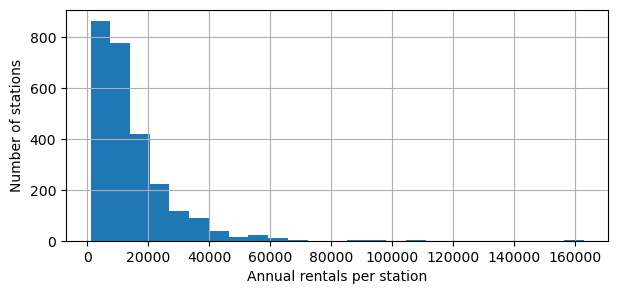

In [46]:
bike["annual_rentals"].hist(bins=25, figsize=(7, 3))
plt.xlabel("Annual rentals per station")
plt.ylabel("Number of stations")
plt.show()

**프로젝트 기록 — 이용 규모**

- 분석 대상 대여소 수와 연간 총대여건수:
- 대여소별 연간 대여건수의 평균과 중앙값:
- 평균과 중앙값이 차이 나는 이유에 대한 내 해석:
- 이용량만을 특성으로 사용한다면 어떤 군집이 형성될 것으로 예상하는가?:

### 평일과 주말의 하루 이용 패턴을 비교한다

2025년의 평일은 261일, 주말은 104일이다. 평일과 주말의 **연간 합계**를 바로 비교하면 날짜 수의 차이가 섞인다. 각 시간대의 총건수를 해당 요일 구분의 날짜 수로 나누어 **하루 평균**을 구하라.

아래 그래프에서 대여(Rental)와 반납(Return)의 시간대별 흐름을 관찰하라.

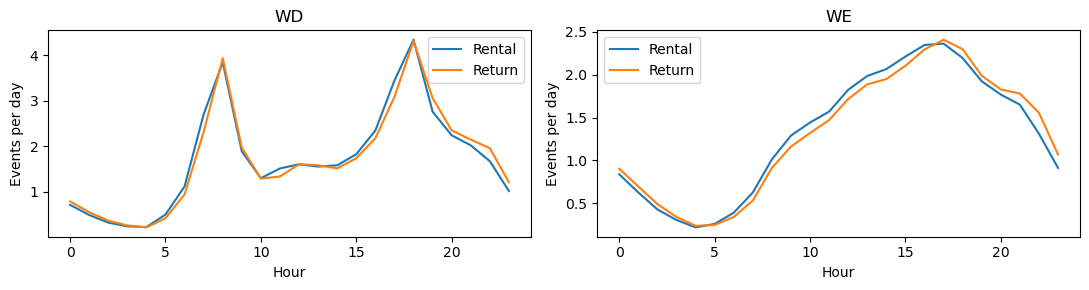

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, day, days in zip(axes, ["wd", "we"], [261, 104]):
    for kind, label in [("r", "Rental"), ("b", "Return")]:
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        ax.plot(range(24), bike[cols].mean().to_numpy() / days, label=label)
    ax.set(title=day.upper(), xlabel="Hour", ylabel="Events per day")
    ax.legend()
plt.tight_layout()
plt.show()

### 나만의 탐색 질문을 만든다

제공된 그래프를 보고 **대여와 반납이 가장 다르게 보이는 시간대 한 곳**을 선택하라. 그 차이를 확인할 수 있는 추가 표나 그래프를 하나 만들어 보라.

**프로젝트 기록 — 나의 EDA**

- 내 질문:
- 이 질문을 확인할 변수와 그래프:
- 실제 관찰한 사실(숫자 또는 그래프 근거):
- 아직 확인할 수 없는 해석:

**AI 체크포인트 — 코드 도움과 해석 검증**

AI에게 다음처럼 요청해도 된다.

> "`bike`에는 대여소별 2025년 평일·주말 시간대별 대여·반납 총건수가 있다. 특정 시간대의 대여와 반납을 비교하는 짧은 pandas 또는 matplotlib 코드를 작성하라. 기존 코드의 변수명만 활용하고 불필요한 예외처리는 넣지 마라."

**AI가 만든 코드를 실행한 후** 실제 그래프가 질문에 답하는지 확인하고, 답하지 못한다면 수정하라.

In [48]:
# TODO: 나의 질문을 확인할 간단한 표 또는 그래프를 작성하라.
# 예: bike[["r_wd_h08", "b_wd_h08"]].describe()

**2단계 마무리 확인**

- [ ] 연간 총건수와 시간대별 총건수의 의미를 구분했다.
- [ ] 전체 이용 규모와 대여소별 이용 규모를 구분했다.
- [ ] 평일과 주말을 비교할 때 날짜 수를 보정해야 하는 이유를 설명했다.
- [ ] 나만의 질문 하나를 만들고 근거가 있는 답을 기록했다.

## 3단계 — 이용 규모보다 이용 패턴에 주목하도록 특성을 만든다

### 왜 건수를 비중으로 바꾸는가?

**K-means는 특성값의 차이가 작은 대여소끼리 묶는다.** 그런데 시간대별 대여건수를 그대로 사용하면, 실제 이용 시간대가 비슷하더라도 **대여량이 많은 곳과 적은 곳을 멀리 떨어진 대여소로 판단**할 수 있다.

예를 들어 두 시간대만 있다고 가정하자.

| 대여소 | 오전 대여 | 오후 대여 | 총대여 |
|---|---:|---:|---:|
| A | 800건 | 200건 | 1,000건 |
| B | 80건 | 20건 | 100건 |
| C | 20건 | 80건 | 100건 |

- **A와 B:** 대여량은 10배 차이 나지만, 모두 **오전 80%·오후 20%**로 이용 패턴이 같다.
- **B와 C:** 총대여량은 같지만, **언제 이용하는지**는 정반대이다.

건수를 그대로 비교하면 A와 B 사이의 차이가 B와 C 사이의 차이보다 훨씬 크다. 따라서 K-means는 **패턴이 같은 A와 B보다 규모가 같은 B와 C를 더 가깝게 볼 수 있다.**

하지만 건수를 비중으로 바꾸면 결과가 달라진다.

| 대여소 | 오전 비중 | 오후 비중 |
|---|---:|---:|
| A | 80% | 20% |
| B | 80% | 20% |
| C | 20% | 80% |

이제 A와 B의 특성값은 완전히 같아진다. 즉, **대여소의 크기보다 이용이 집중되는 시간대**를 중심으로 비교할 수 있다.

**P5에서는 평일과 주말의 날짜 수 차이도 보정한다.** 2025년에는 평일이 261일, 주말이 104일이다. 따라서 평일·주말의 각 시간대 연간 총건수를 해당 날짜 수로 나누어 **하루 평균 대여·반납건수**를 먼저 계산한다. 그다음 한 대여소의 대여 48개 값을 합계로 나누어 비중으로 만들고, 반납 48개 값도 별도로 같은 과정을 거친다.

**평일과 주말을 모두 365로 나누면 어떻게 될까?** 예를 들어 평일과 주말에 하루 평균 100건씩 대여하는 대여소를 생각하자. 실제로는 하루 이용량이 같지만, 평일이 더 많으므로 연간 대여건수는 평일 **26,100건(100 × 261일)**, 주말 **10,400건(100 × 104일)**이 된다.

| 계산 방법 | 평일 하루 평균으로 간주한 값 | 주말 하루 평균으로 간주한 값 | 비중으로 바꾼 결과(평일 : 주말) |
|---|---:|---:|---:|
| **모두 365로 나누기** | 71.5건 | 28.5건 | **71.5% : 28.5%** |
| **각각 261일·104일로 나누기** | 100건 | 100건 | **50% : 50%** |

두 연간 총건수를 모두 365로 나누면 **평일과 주말의 날짜 수 차이가 그대로 남는다.** 나중에 48개 시간대 값의 합으로 다시 나누더라도, 공통으로 나눈 365는 약분되므로 결과가 달라지지 않는다. 결국 하루 이용량이 같은 대여소조차 **평일 이용이 더 집중된 것처럼 잘못 해석할 수 있다.**

그렇다면 **주말에 하루 평균 두 배 많이 이용하는 대여소**는 어떻게 나타날까? 평일에 하루 평균 100건, 주말에 하루 평균 200건을 대여한다고 가정하자.

| 구분 | 평일 | 주말 |
|---|---:|---:|
| 날짜 수 | 261일 | 104일 |
| 하루 평균 대여건수 | 100건 | 200건 |
| 연간 총대여건수 | 26,100건 | 20,800건 |

연간 총건수로만 보면 **평일 대여가 더 많다.** 하지만 하루를 기준으로 비교하면 **주말의 대여량이 평일의 두 배**다. 따라서 날짜 수를 보정한 뒤 비중을 계산하면 다음과 같다.

- **평일 비중의 합:** 100 ÷ (100 + 200) ≈ **0.33**
- **주말 비중의 합:** 200 ÷ (100 + 200) ≈ **0.67**

여기서 **0.67은 연간 대여건수의 67%가 주말에 발생했다는 뜻이 아니다.** 평일과 주말의 **하루 평균 이용량을 같은 기준에서 비교한 값**이다. 실제 연간 대여건수에서 주말이 차지하는 비율은 20,800 ÷ (26,100 + 20,800) ≈ **44.3%**다.

P5에서는 이 방법을 각 시간대에 적용한다. 그러면 **평일과 주말의 날짜 수 차이는 제거하면서, 주말에 하루 평균 더 많이 이용하는 특성과 하루 중 집중되는 시간대는 유지**할 수 있다.

- **대여 비중:** 평일 24개 + 주말 24개 = **48개** (합계 1)
- **반납 비중:** 평일 24개 + 주말 24개 = **48개** (합계 1)
- **K-means 입력:** 대여·반납 비중을 합친 **96개 특성**

**주의:** 여기서 계산한 비중은 *연간 총대여건수에 대한 비중*이 아니라, **평일·주말의 하루 평균값을 합한 값에 대한 비중**이다. 비중으로 바꾸면 이용 규모 정보는 군집화에서 대부분 제외되므로, **군집의 의미를 해석할 때 실제 대여·반납건수도 함께 확인**해야 한다.

In [49]:
rent_cols = [f"r_{d}_h{h:02}" for d in ("wd", "we") for h in range(24)]
return_cols = [f"b_{d}_h{h:02}" for d in ("wd", "we") for h in range(24)]

# 평일과 주말의 날짜 수 차이 보정
daily = bike[rent_cols + return_cols].astype(float).copy()
daily[rent_cols[:24] + return_cols[:24]] /= 261
daily[rent_cols[24:] + return_cols[24:]] /= 104

rent_share = daily[rent_cols].div(daily[rent_cols].sum(axis=1), axis=0)
return_share = daily[return_cols].div(daily[return_cols].sum(axis=1), axis=0)
X = pd.concat([rent_share, return_share], axis=1)
X.head()

,r_wd_h00,r_wd_h01,r_wd_h02,r_wd_h03,r_wd_h04,r_wd_h05,r_wd_h06,r_wd_h07,r_wd_h08,r_wd_h09,...,b_we_h14,b_we_h15,b_we_h16,b_we_h17,b_we_h18,b_we_h19,b_we_h20,b_we_h21,b_we_h22,b_we_h23
0,0.010216,0.006968,0.005036,0.003063,0.003104,0.003186,0.008756,0.008653,0.030462,0.036156,...,0.030882,0.035997,0.035898,0.037423,0.038013,0.032308,0.029899,0.027440,0.023457,0.015540
1,0.014830,0.011511,0.007389,0.004537,0.002385,0.001789,0.003007,0.009593,0.013456,0.021882,...,0.037648,0.039924,0.044243,0.045294,0.046169,0.039165,0.032161,0.028892,0.024515,0.016343
2,0.012695,0.008849,0.007274,0.006440,0.004865,0.003984,0.001807,0.009961,0.027381,0.019922,...,0.035953,0.034202,0.035953,0.041339,0.036760,0.032317,0.024103,0.023026,0.020871,0.011850
3,0.016125,0.012192,0.008888,0.005034,0.004405,0.001809,0.001966,0.009832,0.017226,0.014158,...,0.029908,0.029669,0.041153,0.041871,0.046896,0.041153,0.029669,0.026080,0.028472,0.016031
4,0.013890,0.011287,0.005969,0.004300,0.002376,0.001216,0.005714,0.013211,0.012617,0.008458,...,0.034049,0.042956,0.055312,0.064291,0.061848,0.047123,0.045327,0.036779,0.030745,0.016306


### 만든 특성의 의미를 해석한다

비중으로 바뀌면 값의 단위가 '건수'에서 '비율'로 달라진다. 다음 결과를 읽고 답하라.

In [50]:
print("군집화 특성 수:", X.shape[1])
print("대여 비중 합:", rent_share.iloc[0].sum().round(3))
print("반납 비중 합:", return_share.iloc[0].sum().round(3))
X.iloc[:3, :6].round(3)

군집화 특성 수: 96
대여 비중 합: 1.0
반납 비중 합: 1.0


,r_wd_h00,r_wd_h01,r_wd_h02,r_wd_h03,r_wd_h04,r_wd_h05
0,0.010,0.007,0.005,0.003,0.003,0.003
1,0.015,0.012,0.007,0.005,0.002,0.002
2,0.013,0.009,0.007,0.006,0.005,0.004


**프로젝트 기록 — 특성 설계의 판단 근거**

- 건수를 그대로 사용하면 어떤 대여소들이 비슷하다고 판단될 가능성이 큰가?:
- 시간대별 비중을 사용하면 무엇을 더 잘 비교할 수 있는가?:
- 날짜 수 보정을 생략하면 평일과 주말의 비교가 어떻게 달라지겠는가?:
- 대여·반납의 총규모 정보 중 비중 변환 뒤에는 직접 알 수 없는 것은 무엇인가?:

**AI 체크포인트 — 수식 검토**

> "평일·주말 시간대별 **연간 총건수**를 각각 261과 104로 나눈 뒤, 대여 48개와 반납 48개를 각각 합계 1로 만드는 이유를 설명하라. '비중은 연간 총건수 대비 비율'이라고 주장한다면 맞는지 검토하라."

AI의 설명이 실제 코드의 **분모**와 일치하는지 직접 확인하라.

## 4단계 — K-means로 대여소 유형을 발견한다

### 몇 개의 군집이 적절한가?

K-means는 **96개 특성을 종합하여 다른 대여소들과 패턴이 비슷한 곳**을 같은 군집으로 묶는다. 먼저 군집 수 `k`를 2~6으로 변경해 **실루엣 점수**를 비교하라.

실루엣 점수가 높을수록 군집이 상대적으로 잘 구분된다는 뜻이다. 그러나 **점수 하나만으로 실질적으로 의미 있는 유형이 존재한다고 결론 내리지 마라.** 군집 크기와 군집별 패턴도 함께 살펴야 한다.

In [51]:
results = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X)
    score = silhouette_score(X, labels, sample_size=500, random_state=42)
    results.append([k, score])

scores = pd.DataFrame(results, columns=["k", "silhouette"])
scores

c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on

,k,silhouette
0,2,0.397923
1,3,0.150857
2,4,0.140263
3,5,0.141498
4,6,0.103869


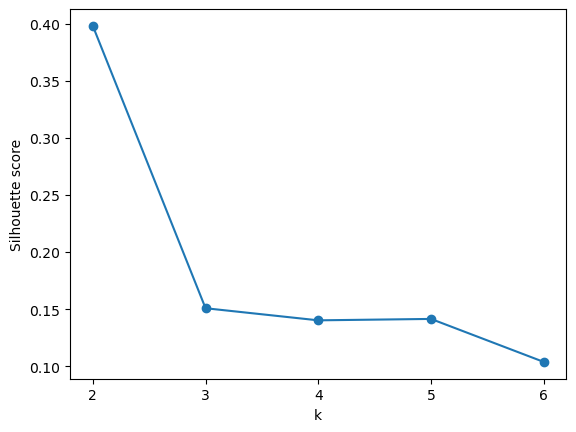

In [52]:
scores.plot(x="k", y="silhouette", marker="o", legend=False)
plt.xticks(scores["k"])
plt.ylabel("Silhouette score")
plt.show()

### 군집 수를 선택하고 패턴을 확인한다

아래 `K`에 **직접 선택한 군집 수**를 입력하라. 네 그래프는 평일 대여, 주말 대여, 평일 반납, 주말 반납의 **군집별 평균 비중**이다. 군집 번호는 임의로 붙은 표식이다.

**중요:** 그래프의 세로축은 *각 군집의 시간대별 보정 비중*이며, 대여소 한 곳의 하루 평균 **절대 건수**가 아니다.

c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(
C:\Users\gslee\AppData\Local\Temp\ipykernel_15496\3419795310.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  bike["cluster"] = model.fit_predict(X)


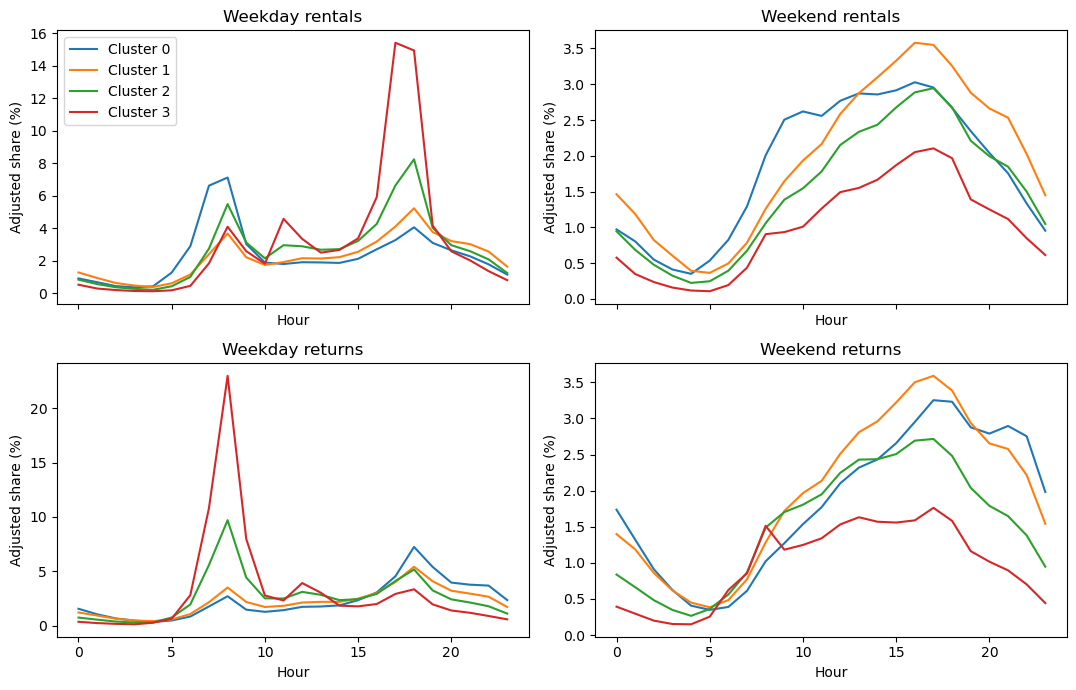

In [53]:
K = 4  # TODO: 실루엣 점수와 군집 해석을 근거로 직접 선택
model = KMeans(n_clusters=K, n_init=10, random_state=42)
bike["cluster"] = model.fit_predict(X)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
parts = [rent_cols[:24], rent_cols[24:], return_cols[:24], return_cols[24:]]
titles = ["Weekday rentals", "Weekend rentals", "Weekday returns", "Weekend returns"]
for ax, cols, title in zip(axes.flat, parts, titles):
    for group, rows in X.groupby(bike["cluster"]):
        ax.plot(range(24), rows[cols].mean().to_numpy() * 100, label=f"Cluster {group}")
    ax.set(title=title, xlabel="Hour", ylabel="Adjusted share (%)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

### 군집 이름을 바로 정하지 말고 증거부터 기록한다

각 군집의 **크기**와 **시간대별 특징**을 확인한 다음 잠정적인 이름을 붙여라. 예를 들어 '출근 대여 집중형'이라고 부르려면 다른 군집과 비교해 출근 시간대의 대여 비중이 높다는 그래프 근거가 필요하다.

In [54]:
bike["cluster"].value_counts().sort_index()

cluster
0     845
1    1149
2     485
3     104
Name: count, dtype: int64

**프로젝트 기록 — 군집 수와 유형 발견**

- `k`별 실루엣 점수와 내가 고른 `K`:
- 선택 이유(점수·군집 크기·그래프 근거):
- 가장 눈에 띄는 군집 두 개와 그 이유:
- 군집마다 임시로 붙인 이름과 그 증거:
- 실루엣 점수만으로는 답할 수 없는 질문 한 가지:

**AI 체크포인트 — 군집 이름 검토**

> "다음은 K-means 군집별 시간대 이용 비중 그래프에서 내가 관찰한 사실이다: [내 관찰 내용]. 각 군집에 잠정적인 이름을 제안하되, 통근·여가 목적을 확정하지 말고 이름의 근거와 반례 가능성을 함께 제시하라."

제안받은 이름 중 **데이터가 뒷받침하지 못하는 이름**이 있으면 수정하라.

### 군집 중심(센트로이드)과 실제 대여소를 비교한다

앞의 그래프에서 비슷한 이용 패턴을 가진 대여소들이 같은 군집으로 묶이는 것을 확인했다. **그렇다면 같은 군집에 속한 대여소들은 정말 모두 비슷할까?**

K-means는 군집마다 **중심점(centroid)**을 계산한다. 이는 해당 군집에 속한 대여소들의 **96개 특성값을 각각 평균한 패턴**이다. 중심점 자체가 실제 대여소인 것은 아니다.

각 대여소의 특성값을 자기 군집의 중심점과 비교하면 다음을 확인할 수 있다.

- **중심에 가까운 대여소:** 그 군집의 전형적인 이용 패턴을 보여주는 사례다.
- **중심에서 먼 대여소:** 같은 군집 안에서도 상대적으로 다른 이용 패턴을 가진 사례다.

`model.transform(X)`는 **각 대여소와 모든 군집 중심 사이의 거리**를 계산한다. 그중 가장 작은 값을 `center_gap`으로 저장한다. **값이 작을수록 군집 중심에 가깝다.** 앞의 `day_gap`과는 다른 지표이며, `center_gap`이 크다고 해서 잘못 군집화되었다는 뜻은 아니다.


In [55]:
bike = bike.copy()  # 데이터프레임의 메모리 구조를 정리한 뒤 새 열을 추가한다.
bike["center_gap"] = model.transform(X).min(axis=1)

near = bike.loc[bike.groupby("cluster")["center_gap"].idxmin(),
                ["cluster", "station_name", "center_gap"]].assign(구분="중심에 가까움")
far = bike.loc[bike.groupby("cluster")["center_gap"].idxmax(),
               ["cluster", "station_name", "center_gap"]].assign(구분="중심에서 멂")

pd.concat([near, far]).sort_values(["cluster", "center_gap"])[
    ["cluster", "구분", "station_name", "center_gap"]
].round(3)

,cluster,구분,station_name,center_gap
1560,0,중심에 가까움,석촌동 주민센터,0.032
2137,0,중심에서 멂,사당역 1번출구,0.236
1848,1,중심에 가까움,길동 마루빌딩,0.031
2268,1,중심에서 멂,국립중앙박물관 -용산가족공원 앞,0.226
306,2,중심에 가까움,염리초등학교 앞,0.042
2563,2,중심에서 멂,국회박물관,0.485
1444,3,중심에 가까움,포스코사거리(기업은행),0.065
1961,3,중심에서 멂,철도교통관제센터 정문 앞,0.372


표에 나타난 대여소 두 곳을 실제 그래프로 비교해 보자. 아래 그래프는 관심 군집의 **평일 대여 패턴**을 중심점 및 실제 대여소 두 곳에서 비교한다. `GROUP`을 다른 군집 번호로 바꾸어도 된다.

**주의:** 중심까지의 거리는 96개 특성을 모두 사용해 계산했다. 아래는 그중 **평일 대여 24개만** 보여주므로, 그래프가 비슷하더라도 주말·반납 패턴에서는 큰 차이가 있을 수 있다.


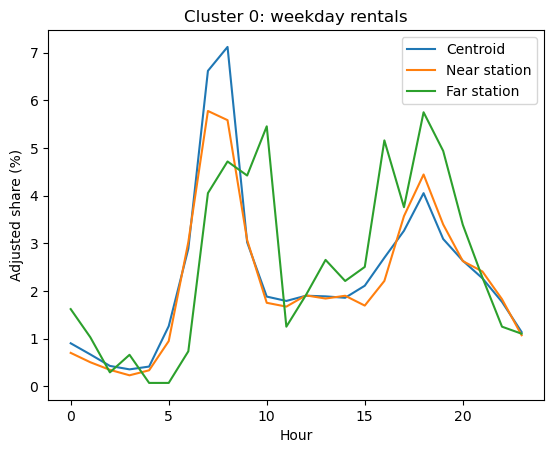

In [56]:
GROUP = 0  # TODO: 관심 있는 군집 번호로 바꾸어 보라.
selected = bike[bike["cluster"] == GROUP]
near_id = selected["center_gap"].idxmin()
far_id = selected["center_gap"].idxmax()
cols = rent_cols[:24]  # 평일 대여 24개 시간대

plt.plot(range(24), X.loc[selected.index, cols].mean().to_numpy() * 100, label="Centroid")
plt.plot(range(24), X.loc[near_id, cols].to_numpy() * 100, label="Near station")
plt.plot(range(24), X.loc[far_id, cols].to_numpy() * 100, label="Far station")
plt.title(f"Cluster {GROUP}: weekday rentals")
plt.xlabel("Hour")
plt.ylabel("Adjusted share (%)")
plt.legend()
plt.show()

### 군집마다 자전거가 모이거나 빠져나가는 시간대가 다른가?

군집은 **시간대별 이용 비중**으로 만들었으므로, 여기서는 실제 대여·반납 **건수**로 돌아가 군집별 특징을 더 살펴본다.

한 대여소에서 **순유입 = 반납건수 − 대여건수**로 계산하자.

- **양수:** 반납이 더 많아 해당 시간대에 자전거가 모이는 경향을 나타낸다.
- **음수:** 대여가 더 많아 해당 시간대에 자전거가 빠져나가는 경향을 나타낸다.
- **0에 가까움:** 대여와 반납 건수가 비슷하다.

2025년 평일은 261일이므로 각 시간대의 **연간 반납−대여 차이**를 261로 나누어 평일 하루 평균을 구한다. 그런 다음 군집별로 **대여소 한 곳당 평균 순유입**을 계산해 비교한다.

그래프에서 **어떤 군집이 오전에 음수이고 오후에 양수로 바뀌는지**, 혹은 그 반대인지 확인하라. 실제 자전거 부족·재배치 필요성을 판단하려면 자전거 재고, 거치대 수, 재배치 기록 등의 추가 자료가 필요하다.


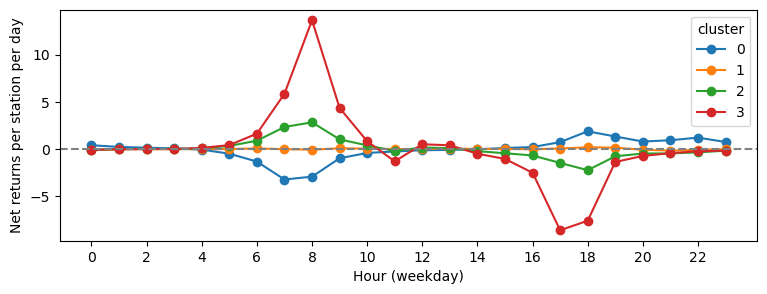

,8,18
cluster,,
0,-2.9,1.9
1,-0.1,0.2
2,2.8,-2.2
3,13.6,-7.6


In [57]:
net_wd = pd.DataFrame({
    h: (bike[f"b_wd_h{h:02}"] - bike[f"r_wd_h{h:02}"]) / 261
    for h in range(24)
})
net_by_cluster = net_wd.groupby(bike["cluster"]).mean()

net_by_cluster.T.plot(figsize=(9, 3), marker="o")
plt.axhline(0, color="gray", linestyle="--")
plt.xticks(range(0, 24, 2))
plt.xlabel("Hour (weekday)")
plt.ylabel("Net returns per station per day")
plt.show()

net_by_cluster[[8, 18]].round(1)  # 오전 8시와 오후 6시의 군집별 비교

**프로젝트 기록 — 발견한 군집을 검증하고 활용한다**

- 관심 군집에서 중심에 가까운 대여소와 먼 대여소의 이름:
- 두 대여소의 시간대별 패턴에서 발견한 공통점과 차이:
- 평일 오전·오후 순유입의 부호가 다르게 나타난 군집과 근거:
- 이 결과를 실제 운영에 적용하기 전에 확인해야 할 추가 자료:

**AI 체크포인트 — 군집 결과를 과장하지 않기**

> "다음은 내 군집별 순유입 그래프에서 관찰한 내용이다: [내 관찰]. 이 결과만으로 자전거 재배치가 필요하다고 결론 낼 수 있는지 검토하고, 부족한 자료를 알려 달라."

AI의 설명에서 **데이터가 직접 보여주는 사실**과 **추가 확인이 필요한 추측**을 구분하라.

**4단계 마무리 확인**

- [ ] `K`를 직접 선택한 근거가 있다.
- [ ] 군집 번호가 아니라 **시간대별 패턴**으로 유형을 설명했다.
- [ ] 같은 군집의 대여소들이 실제로 모두 동일하다고 주장하지 않았다.
- [ ] 군집 중심과 가까운 대여소·먼 대여소를 비교했다.
- [ ] 군집별 순유입의 부호와 크기를 실제 건수로 해석했다.

## 5단계 — 평일·주말 유사성에 관한 두 질문을 구분한다

### 한 대여소 안에서 평일과 주말이 얼마나 다른가?

4단계에서는 **대여소 사이의 유사성**을 기준으로 군집을 만들고, 군집 중심과 순유입까지 확인했다. 이제 관점을 바꾸어 **같은 대여소의 평일 패턴과 주말 패턴**을 비교한다.

평일 대여 24개, 주말 대여 24개를 **각각 합계 1**로 변환하여 하루 중 어느 시간에 이용되는지를 비교한다. 반납도 동일하게 처리한다. 여기서는 **이용 시간대의 모양만 비교**하기 위해 평일·주말의 이용량 크기는 제외한다.

`day_gap`은 **평일 대여와 주말 대여의 시간대별 비중 차이**, 그리고 **평일 반납과 주말 반납의 시간대별 비중 차이**를 각각 0~1로 계산해 평균한 값이다. 두 비중 분포의 차이에서 절댓값의 합은 최대 2이므로, 코드에서는 대여·반납의 차이를 모두 더한 뒤 **4로 나눈다.** **0에 가까울수록 평일·주말의 시간대별 모양이 비슷하다.** 이는 군집 번호가 아니라 **개별 대여소의 특성**이다.

In [58]:
def day_pattern(day):
    blocks = []
    for kind in ("r", "b"):
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        counts = bike[cols]
        blocks.append(counts.div(counts.sum(axis=1), axis=0))
    return pd.concat(blocks, axis=1)

weekday = day_pattern("wd")
weekend = day_pattern("we")
bike["day_gap"] = abs(weekday.to_numpy() - weekend.to_numpy()).sum(axis=1) / 4

pd.concat([bike.nsmallest(3, "day_gap"), bike.nlargest(3, "day_gap")])[["station_name", "day_gap"]]

,station_name,day_gap
1661,등나무 근린공원(시립북서울미술관 앞),0.070024
2001,한내 행복발전소 옆,0.074100
1961,철도교통관제센터 정문 앞,0.082735
1605,롯데 R&D 센터,0.540865
775,코오롱One&Only타워,0.539547
1164,벽산 디지털밸리 5차,0.508994


### 실제 대여소 두 곳을 골라 패턴을 비교한다

아래 코드는 `day_gap`이 가장 큰 대여소를 보여준다. `idxmax()`를 `idxmin()`으로 바꾸어 차이가 가장 작은 대여소도 확인하라.

이 그래프에서 평일·주말 각각의 비중 합은 1이다. 따라서 **이용 시간의 차이**를 보여주지만 **평일·주말의 총이용량 차이**를 직접 보여주지는 않는다.

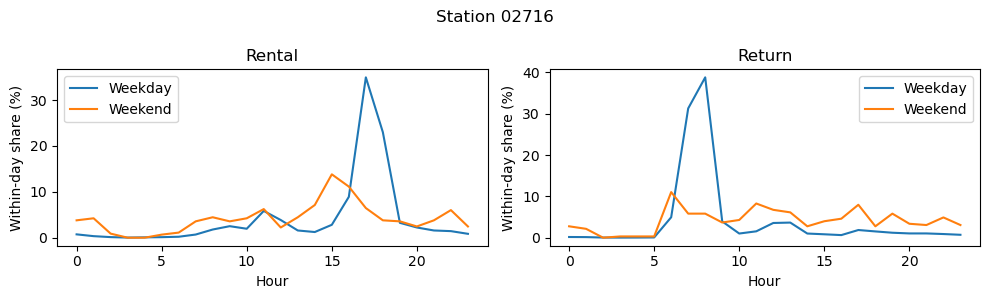

In [59]:
ROW = bike["day_gap"].idxmax()  # TODO: idxmin()으로 바꿔 비교
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, kind, title in zip(axes, ("r", "b"), ("Rental", "Return")):
    for day, label in (("wd", "Weekday"), ("we", "Weekend")):
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        values = bike.loc[ROW, cols].to_numpy(dtype=float)
        ax.plot(range(24), values / values.sum() * 100, label=label)
    ax.set(title=title, xlabel="Hour", ylabel="Within-day share (%)")
    ax.legend()
plt.suptitle(f"Station {bike.loc[ROW, 'station_id']}")
plt.tight_layout()
plt.show()

### 같은 시간대 패턴이라도 주말 이용량은 다를 수 있다

`weekend_level`은 평일 하루 평균 대여량과 주말 하루 평균 대여량 가운데 **주말이 차지하는 비중**이다.

- `weekend_level = 0.5`: 평일과 주말의 하루 평균 대여량이 같다.
- `weekend_level > 0.5`: 주말의 하루 평균 대여량이 더 많다.
- `day_gap`은 **언제** 이용하는지, `weekend_level`은 **얼마나** 이용하는지에 관한 정보다.

두 지표가 서로 다른 질문에 답한다는 사실을 확인하라.

In [60]:
weekday_avg = bike[rent_cols[:24]].sum(axis=1) / 261
weekend_avg = bike[rent_cols[24:]].sum(axis=1) / 104
bike["weekend_level"] = weekend_avg / (weekday_avg + weekend_avg)

bike.groupby("cluster").agg(
    stations=("station_id", "size"),
    rentals=("annual_rentals", "median"),
    returns=("annual_returns", "median"),
    day_gap=("day_gap", "mean"),
    weekend_level=("weekend_level", "mean")
).round(3)

,stations,rentals,returns,day_gap,weekend_level
cluster,,,,,
0,845,9749.0,9329.0,0.233,0.439
1,1149,10812.0,10707.0,0.180,0.469
2,485,11835.0,12033.0,0.254,0.365
3,104,11072.0,11776.5,0.375,0.242


### 평일에 유사한 대여소가 주말에도 유사한가?

이 질문은 앞의 `day_gap`과도 다르다. **다른 대여소끼리** 평일 패턴만으로 한 번 군집화하고, 주말 패턴만으로 다시 군집화한다. 그 결과를 교차표로 비교하라.

- 같은 **행**: 평일 패턴이 유사한 대여소의 집합
- 같은 **열**: 주말 패턴이 유사한 대여소의 집합
- 같은 **칸**: 평일과 주말에서 각각 같은 군집에 속한 대여소 집합

**평일 군집 0과 주말 군집 0이 같은 의미라는 뜻은 아니다.** 두 모델은 각각 독립적으로 학습했다.

In [61]:
K_DAY = 3  # TODO: 평일·주말 각각의 군집 수
bike["weekday_group"] = KMeans(n_clusters=K_DAY, n_init=10, random_state=42).fit_predict(weekday)
bike["weekend_group"] = KMeans(n_clusters=K_DAY, n_init=10, random_state=42).fit_predict(weekend)
pd.crosstab(bike["weekday_group"], bike["weekend_group"])

c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(
c:\Users\gslee\miniforge3\Lib\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=11.
  warnings.warn(


weekend_group,0,1,2
weekday_group,,,
0,219,720,380
1,751,137,44
2,45,65,222


**프로젝트 기록 — 평일·주말 패턴 비교**

- `day_gap`이 큰 대여소와 작은 대여소에서 관찰한 차이:
- 한 대여소에서 평일과 주말의 **시간대 패턴이 유사하다**는 말의 의미:
- 평일에 **같은 군집인 두 대여소**가 주말에도 같은 군집인지 확인한 사례:
- `day_gap`과 `weekend_level`의 차이를 실제 수치로 설명:
- 평일·주말 분리 군집화 결과가 통합 군집화에서 놓치는 정보를 보여주었는가?:

**AI 체크포인트 — 유사성 개념 확인**

> "K-means의 군집 번호, `day_gap`, 평일·주말 분리 군집화의 교차표가 각각 무엇을 비교하는지 설명하라. 세 결과를 같은 의미로 혼동하면 어떤 오류가 생기는지 사례로 보여 달라."

AI가 **'평일 0번 군집 = 주말 0번 군집'**이라고 말하면 왜 잘못된 설명인지 직접 반박하라.

## 6단계 — 분석 결과를 검증하고 운영 방안을 제안한다

### 패턴 비중과 실제 이용 규모를 함께 살펴본다

4단계에서 군집별 순유입을 살펴봤다. 이번에는 관심 군집의 **대여·반납 건수 자체를 나란히** 확인한다. 시간대별 비중이 높다고 해서 그 시간대의 대여·반납 **절대 건수**가 큰 것은 아니다. 관심 있는 군집에서 **대여소 한 곳당 하루 평균 대여·반납건수**를 함께 확인하라.

어떤 시간대에 대여가 반납보다 많다면 자전거가 빠져나가는 경향을 시사할 수 있다. 그러나 **실제 재배치 필요성**은 이용 가능한 자전거 수, 거치대 용량, 운영·정비 기록 등 추가 자료가 있어야 판단할 수 있다.

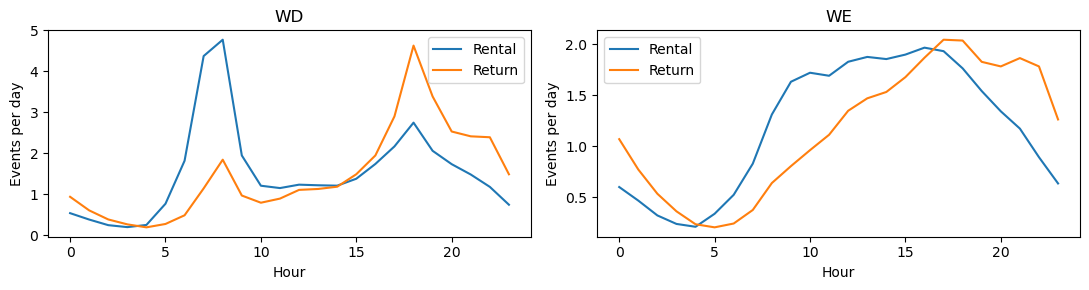

In [62]:
GROUP = 0  # TODO: 관심 있는 군집 번호
selected = bike[bike["cluster"] == GROUP]

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, day, days in zip(axes, ("wd", "we"), (261, 104)):
    for kind, label in (("r", "Rental"), ("b", "Return")):
        cols = [f"{kind}_{day}_h{h:02}" for h in range(24)]
        ax.plot(range(24), selected[cols].mean().to_numpy() / days, label=label)
    ax.set(title=day.upper(), xlabel="Hour", ylabel="Events per day")
    ax.legend()
plt.tight_layout()
plt.show()

### 월별 이용 패턴도 함께 확인한다

`m01`~`m12`는 **월별 대여 총건수**다. 월별 비중을 그리면 군집마다 계절적 집중 시기가 다른지 탐색할 수 있다. 다만 월별 날짜 수와 날씨 차이는 별도로 보정하지 않았으므로, **월별 비중을 계절의 인과효과로 해석하지 마라.**

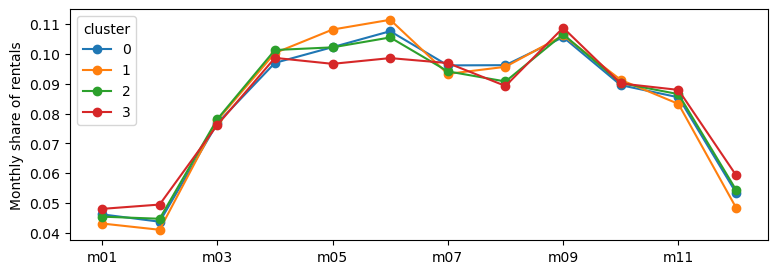

In [63]:
months = [f"m{m:02}" for m in range(1, 13)]
monthly_share = bike[months].div(bike["annual_rentals"], axis=0)
monthly_share.groupby(bike["cluster"]).mean().T.plot(marker="o", figsize=(9, 3))
plt.ylabel("Monthly share of rentals")
plt.show()

### 나의 추가 분석을 수행한다

다음 중 **하나를 선택**해 기존 결과를 다시 살펴보라.

- **A — 군집 수의 영향:** `K`를 하나 더 선택해 군집 크기와 시간대별 패턴이 어떻게 달라지는지 비교하라.
- **B — 대여소의 차이:** 관심 있는 군집에서 `day_gap`이 가장 큰 대여소와 가장 작은 대여소를 찾아 비교하라.
- **C — 운영 가설:** 대여·반납 시간대 차이가 두드러지는 군집을 선택하고, **수치 근거를 하나 이상** 제시하라.

복잡한 코드를 새로 작성할 필요는 없다. 기존 코드의 `K`, `ROW`, `GROUP` 중 필요한 값을 바꾸거나 짧은 코드를 추가하라.

**AI 체크포인트 — 독립적인 분석 수행**

> "나는 P5에서 [선택한 A/B/C 활동]을 수행하려 한다. 기존 변수 `bike`, `X`, `model`을 유지하면서 필요한 부분만 바꾸는 간단한 코드를 제안하라. 그래프에서 무엇을 확인할지 먼저 질문하라. 결과는 임의로 만들어 내지 마라."

AI의 코드·해석을 검토하고, **스스로 수정한 부분**과 수정 이유를 남겨라.

In [64]:
# TODO: A/B/C 중 선택한 추가 분석을 작성하라.
# 기존 셀을 다시 실행하고 결과를 비교해도 된다.

### 군집에 이름을 붙이고 근거 있는 운영 방안을 제안한다

아래 표를 **실제 결과**를 보고 채워라. `K`를 바꾸었다면 군집 수에 맞게 행을 추가하거나 줄여라.

| 군집 | 평일 특징(대여·반납) | 주말 특징(대여·반납) | `day_gap`·이용 규모 | 잠정적 이름과 근거 |
|---|---|---|---|---|
| 0 | | | | |
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |

**프로젝트 기록 — 최종 판단**

- 군집 수 `K`를 선택한 이유를 **실루엣 점수와 그래프**로 설명하라.
- **대여소 사이의 유사성**과 **한 대여소 안의 평일·주말 유사성**을 구분해 서술하라.
- 관심 군집 하나를 선택해 **시간대별 특징 → 운영 가설 → 필요한 추가 자료**를 연결하라.
- AI가 제안한 군집 이름 또는 운영 전략에서 **과장된 부분 하나**를 찾아 수정하라.
- **이번 데이터로 알 수 없는 것 두 가지**를 제시하라.

**해석의 경계:** K-means 군집은 이용 목적의 확정된 분류가 아니다. 대여·반납 비중으로는 실제 재고 부족이나 자전거 재배치 필요성을 단정할 수 없다. 모의 데이터 결과를 서울시 실제 운영 정책의 근거로 사용하지 마라.

### 최종 제출 전 확인

- [ ] 분석 질문과 사전 가설을 작성했다.
- [ ] 연간·월별 총건수와 시간대별 총건수의 의미를 구분했다.
- [ ] 평일·주말의 날짜 수를 보정한 이유를 설명했다.
- [ ] 이용건수를 비중으로 바꾸는 이유를 설명했다.
- [ ] `K`를 직접 선택하고 군집 수의 근거를 제시했다.
- [ ] 군집별 대여·반납 패턴을 실제 그래프로 설명했다.
- [ ] 군집 중심에서 가까운 대여소와 먼 대여소를 비교했다.
- [ ] 군집별 평일 시간대 순유입 결과를 근거와 한계를 구분해 해석했다.
- [ ] `day_gap`과 `weekend_level`이 다른 정보를 뜻한다는 것을 이해했다.
- [ ] 통합 군집화와 평일·주말 분리 군집화가 답하는 질문을 구분했다.
- [ ] AI가 작성한 코드나 해석을 직접 검증하고 수정한 내용을 기록했다.
- [ ] 운영 제안에 근거와 한계를 함께 제시했다.

### 평가 기준 (20점)

| 평가 영역 | 배점 | 확인할 내용 |
|---|---:|---|
| 문제 정의와 데이터 이해 | 4 | 가설, 집계 단위, 원자료의 의미, EDA |
| 특성 설계와 군집 수 선택 | 5 | 날짜 보정, 비중, 실루엣, `K` 선택 근거 |
| 군집 및 평일·주말 유사성 해석 | 5 | 군집 패턴, `day_gap`, 분리 군집화 해석 |
| AI 활용과 독립적 검증 | 3 | 추가 분석, AI 결과 검토, 직접 수정 |
| 최종 운영 제안과 한계 | 3 | 그래프 근거, 무리한 인과 해석 방지 |
| **합계** | **20** | |

**제출물:** 실행한 노트북과 요약 보고서 1~2쪽을 제출하라. **문제 정의 → 데이터 탐색 → 특성 설계 → 군집화 → 평일·주말 비교 → 최종 판단**의 흐름을 유지하라.

## 선택 확장 — 2024년과 비교한다

2024년 대여이력까지 같은 구조로 준비했다면, 2025년에 학습한 K-means 모델을 **변경하지 않고** 2024년 대여소 데이터에 적용할 수 있다. 2024년은 **월~금 262일, 토·일 104일**이므로 날짜 수를 해당 연도에 맞게 보정하라.

아래 코드는 2024년 CSV가 준비된 경우에만 실행한다. 두 연도에 모두 존재하는 대여소끼리 비교하라. 2025년 모델을 2024년에 적용한 것이므로 **각 연도에서 독립적으로 군집화한 결과의 일치율이라고 해석하지 마라.**

```python
old = pd.read_csv("p5_station_profiles_2024.csv", dtype={"station_id": str}).set_index("station_id")
now = bike.set_index("station_id")
common = old.index.intersection(now.index)

old_daily = old.loc[common, rent_cols + return_cols].astype(float).copy()
old_daily[rent_cols[:24] + return_cols[:24]] /= 262
old_daily[rent_cols[24:] + return_cols[24:]] /= 104
old_r = old_daily[rent_cols].div(old_daily[rent_cols].sum(axis=1), axis=0)
old_b = old_daily[return_cols].div(old_daily[return_cols].sum(axis=1), axis=0)
old_group = model.predict(pd.concat([old_r, old_b], axis=1))

pd.crosstab(old_group, now.loc[common, "cluster"].to_numpy(), normalize="index").round(2)
```

**확장 질문:** 2024년과 2025년의 이용 유형 차이가 실제 행동 변화인지, 대여소 신설·폐쇄나 운영 기간 차이 때문인지 구분할 추가 자료를 제안하라.

원자료: [서울 열린데이터광장 — 공공자전거 대여이력](https://data.seoul.go.kr/dataList/OA-15182/F/1/datasetView.do). 실제 원본 CSV 전체에 대한 전처리 검증은 별도로 수행해야 한다.